# 01 – Explorative Datenanalyse (Meilenstein 1)

Hyperion-Spektren (EO-1) landwirtschaftlicher Kulturen. Ziel: Crop **und** Growth Stage bestimmen. Dieses Notebook fasst die EDA zusammen; alle Abbildungen erzeugt `scripts/01_eda.py` reproduzierbar.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image, display, Markdown
from dp2 import config as C, data as D
FIG = C.FIGURES

## Rohdaten

In [2]:
raw_tr, raw_te = D.load_raw()
print(raw_tr.shape, raw_te.shape)
raw_tr.iloc[:5, :8]

(5591, 203) (1397, 201)


,AEZ,Month,Crop,Stage,X427,X437,X447,X457
0,10,8,corn,Critical,NaN,21.380647,19.123425,17.686109
1,10,8,corn,Critical,NaN,20.156616,18.015525,16.671422
2,8,8,corn,Critical,NaN,15.149693,13.715446,13.172751
3,10,8,corn,Critical,NaN,16.668828,14.892895,13.907130
4,10,7,corn,Critical,NaN,17.949177,16.185521,15.237852


In [3]:
bands = D.band_columns(raw_tr)
empty = [b for b in bands if raw_tr[b].isna().all()]
print(f'{len(bands)} Bandspalten, davon {len(empty)} komplett leer')
print('leer (nm):', [int(b[1:]) for b in empty])

198 Bandspalten, davon 67 komplett leer
leer (nm): [427, 925, 933, 943, 953, 963, 973, 1104, 1114, 1124, 1134, 1144, 1155, 1165, 1326, 1336, 1346, 1356, 1366, 1377, 1387, 1397, 1407, 1417, 1427, 1437, 1447, 1457, 1467, 1477, 1488, 1498, 1508, 1770, 1780, 1790, 1800, 1810, 1820, 1831, 1841, 1851, 1861, 1871, 1881, 1891, 1901, 1911, 1921, 1931, 1942, 1952, 1962, 1972, 1982, 1992, 2002, 2012, 2022, 2032, 2042, 2052, 2355, 2365, 2375, 2385, 2395]


Die leeren Bänder liegen exakt auf den **atmosphärischen Wasserdampfbanden** (~1130, ~1400, ~1900 nm), am VNIR/SWIR-Detektorübergang und an den verrauschten Rändern – dort misst Hyperion keine verwertbare Bodenreflexion. Sie werden entfernt, 131 Bänder bleiben.

In [4]:
ds = D.load()
tr = ds.train
print('bereinigt:', tr.shape, '| Duplikate entfernt:', ds.n_duplicates)
pd.crosstab(tr.Crop, tr.Stage).reindex(index=C.CROPS, columns=C.STAGES).fillna(0).astype(int)

bereinigt: (5589, 137) | Duplikate entfernt: 2


Stage,Emerge_VEarly,Early_Mid,Late,Critical,Mature_Senesc,Harvest
Crop,,,,,,
corn,152,212,557,675,399,102
cotton,172,253,0,157,65,11
rice,0,52,41,0,0,0
soybean,106,465,233,652,146,67
winter_wheat,607,0,30,56,379,0


## Klassenverteilung
23 der 30 Crop×Stage-Kombinationen kommen vor; die kleinste (Baumwolle/Ernte) hat nur 11 Proben – Faktor > 60 zur größten. Deshalb wird überall mit Klassengewichten und Balanced Accuracy gearbeitet.

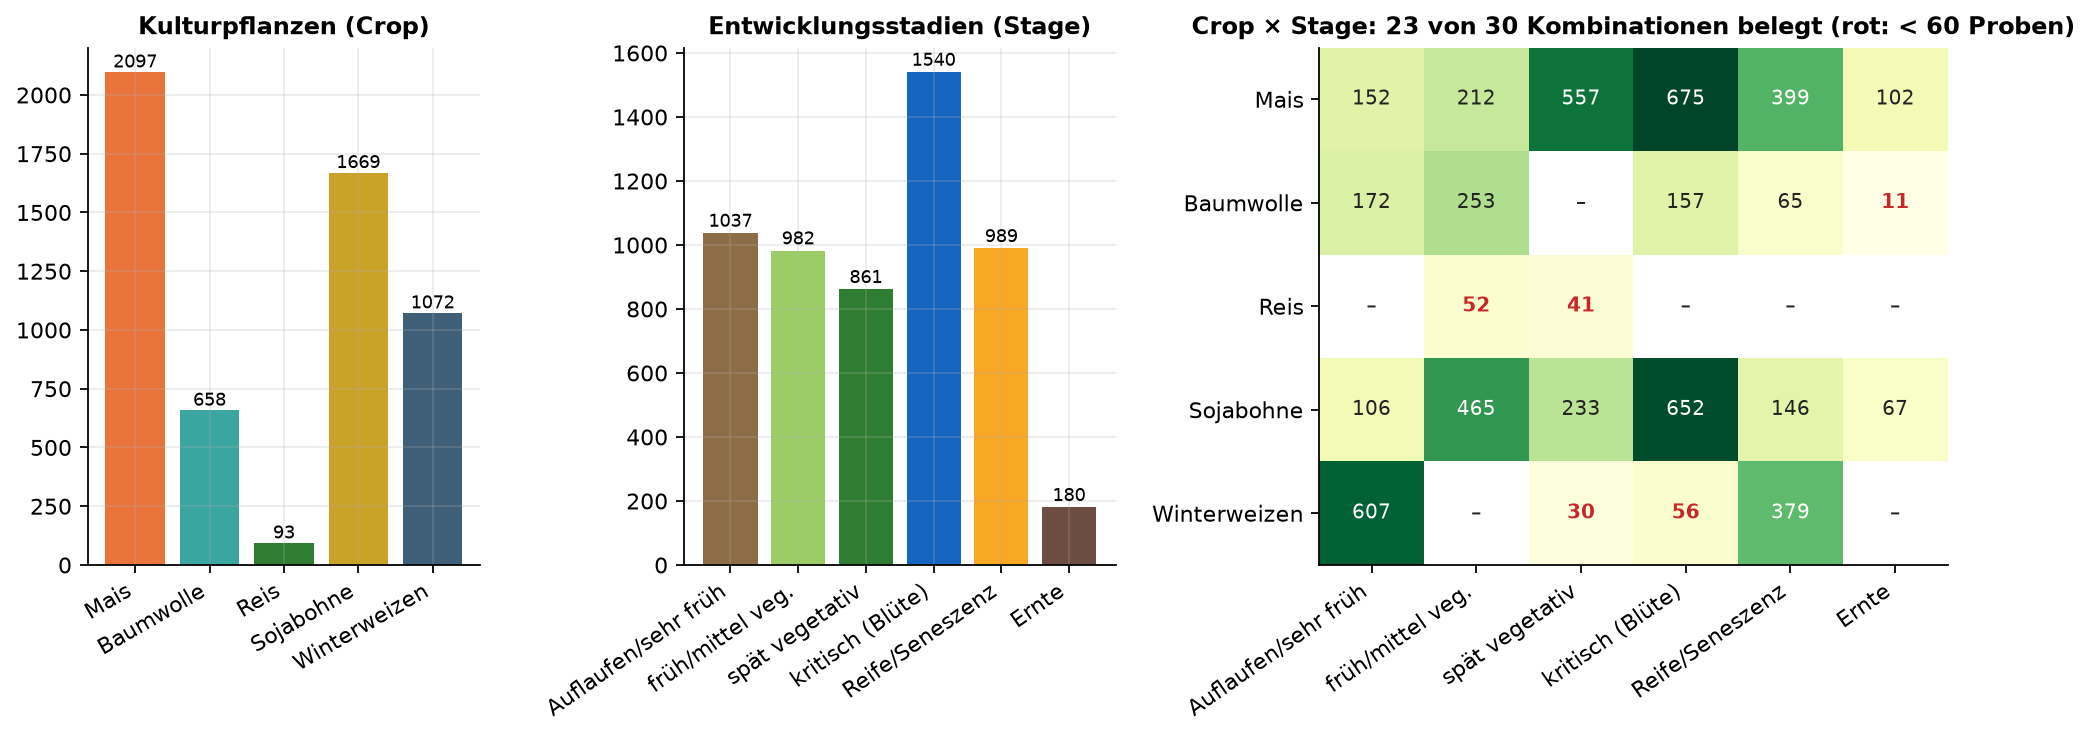

In [5]:
display(Image(FIG / 'eda_class_distribution.png'))

## Metadaten: AEZ und Monat
AEZ und Aufnahmemonat sind stark mit den Klassen verknüpft (Reis nur AEZ 7/August, Winterweizen läuft im Herbst auf). Die Aufgabenstellung erlaubt ihre Nutzung ausdrücklich.

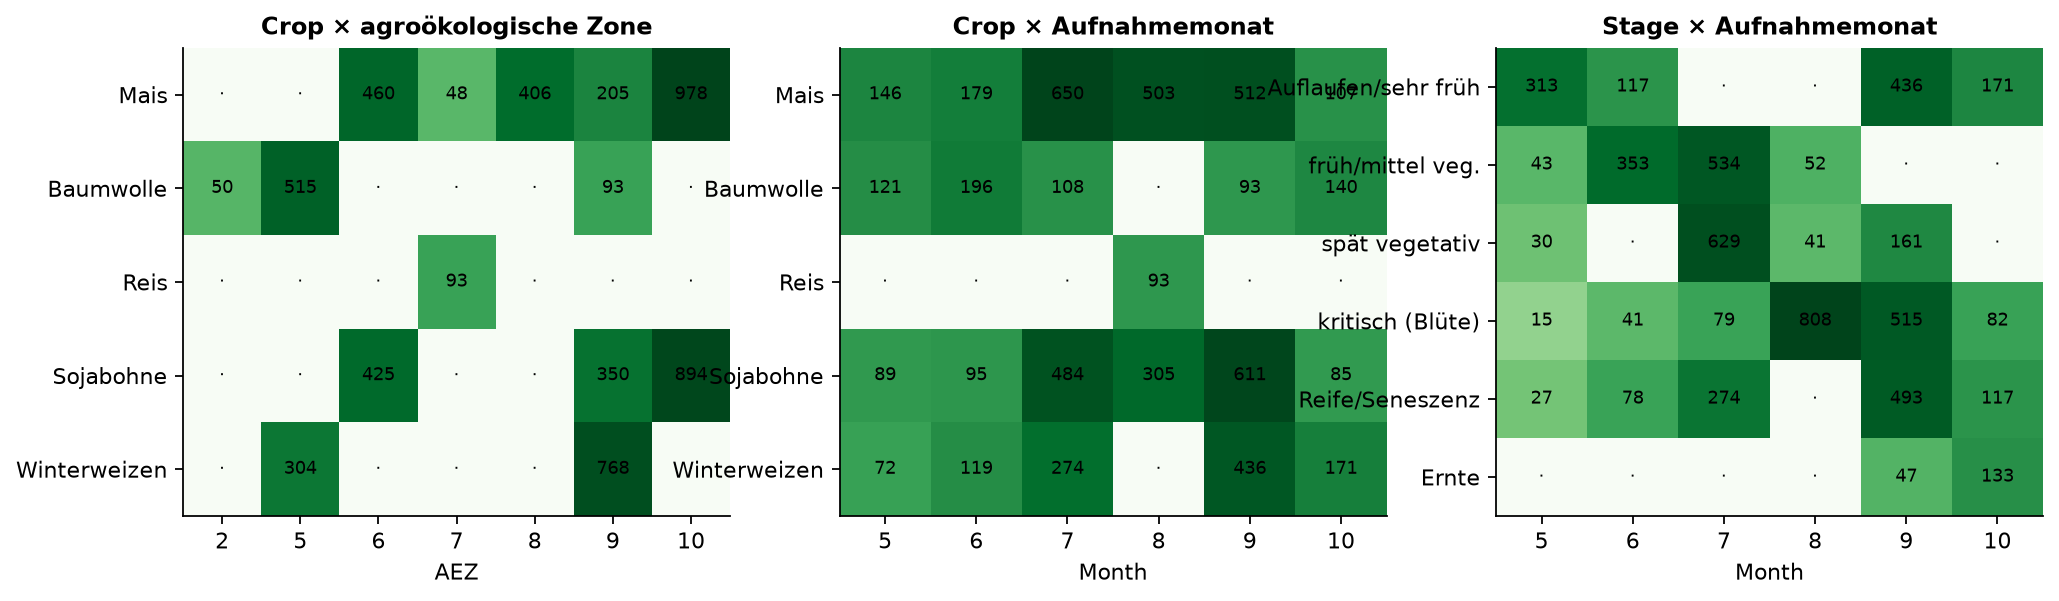

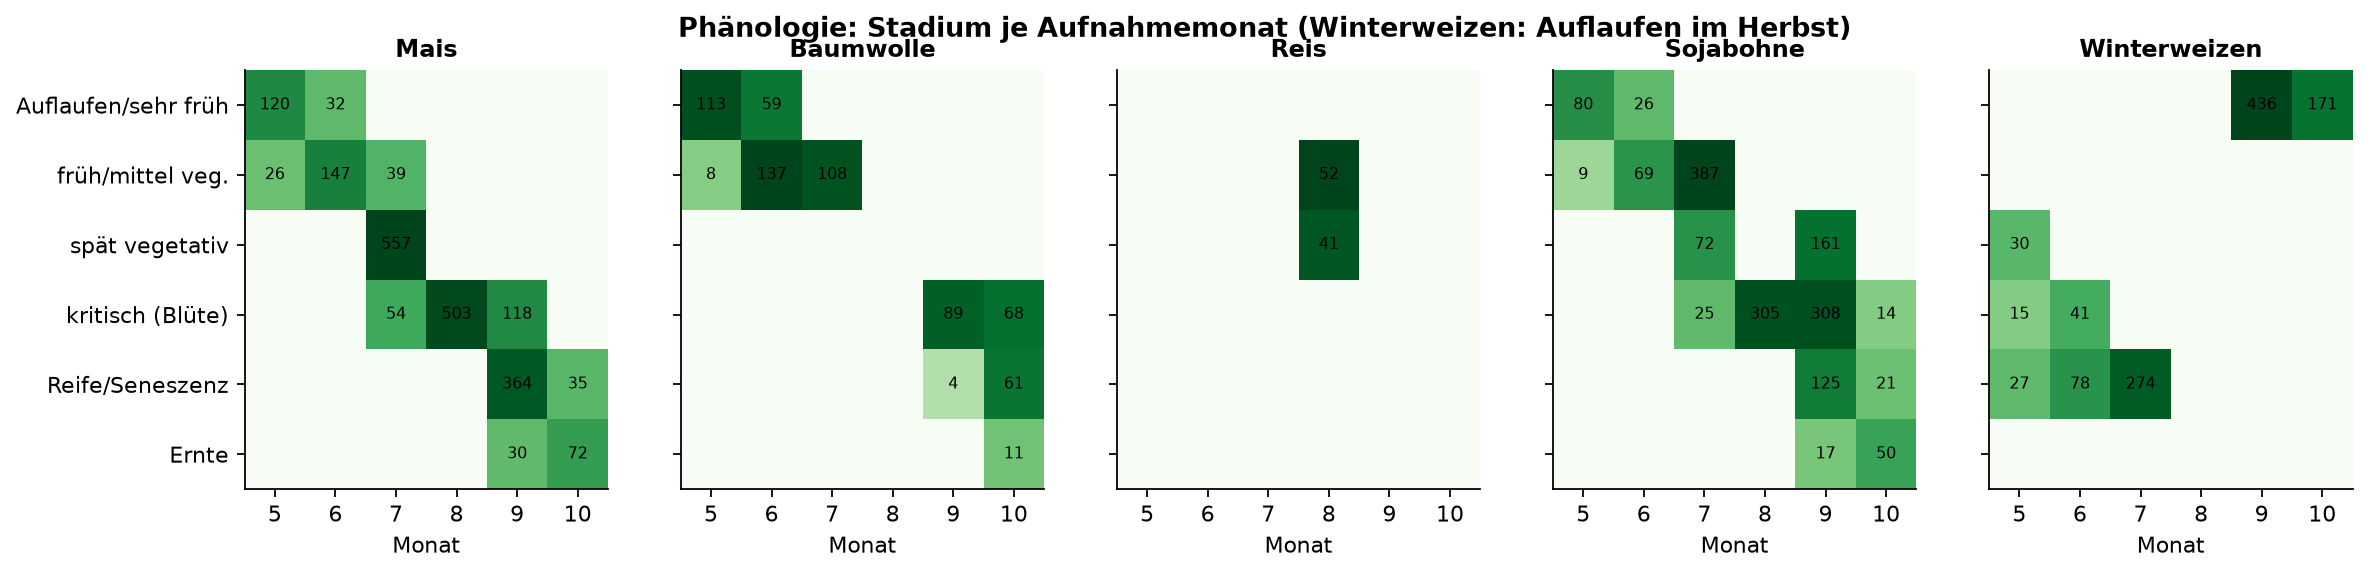

In [6]:
display(Image(FIG / 'eda_metadata.png'))
display(Image(FIG / 'eda_phenology.png'))

## Spektrale Signaturen

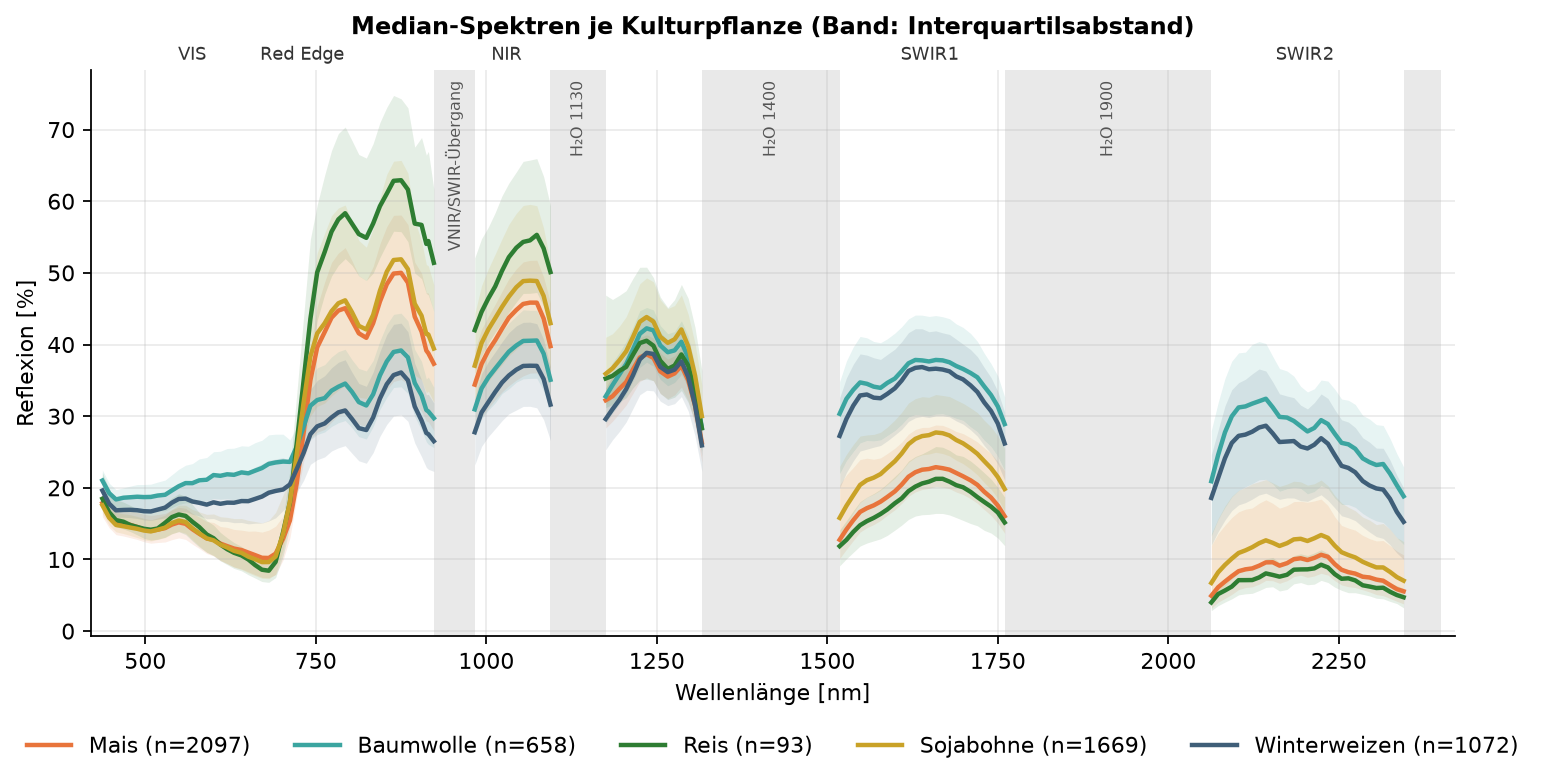

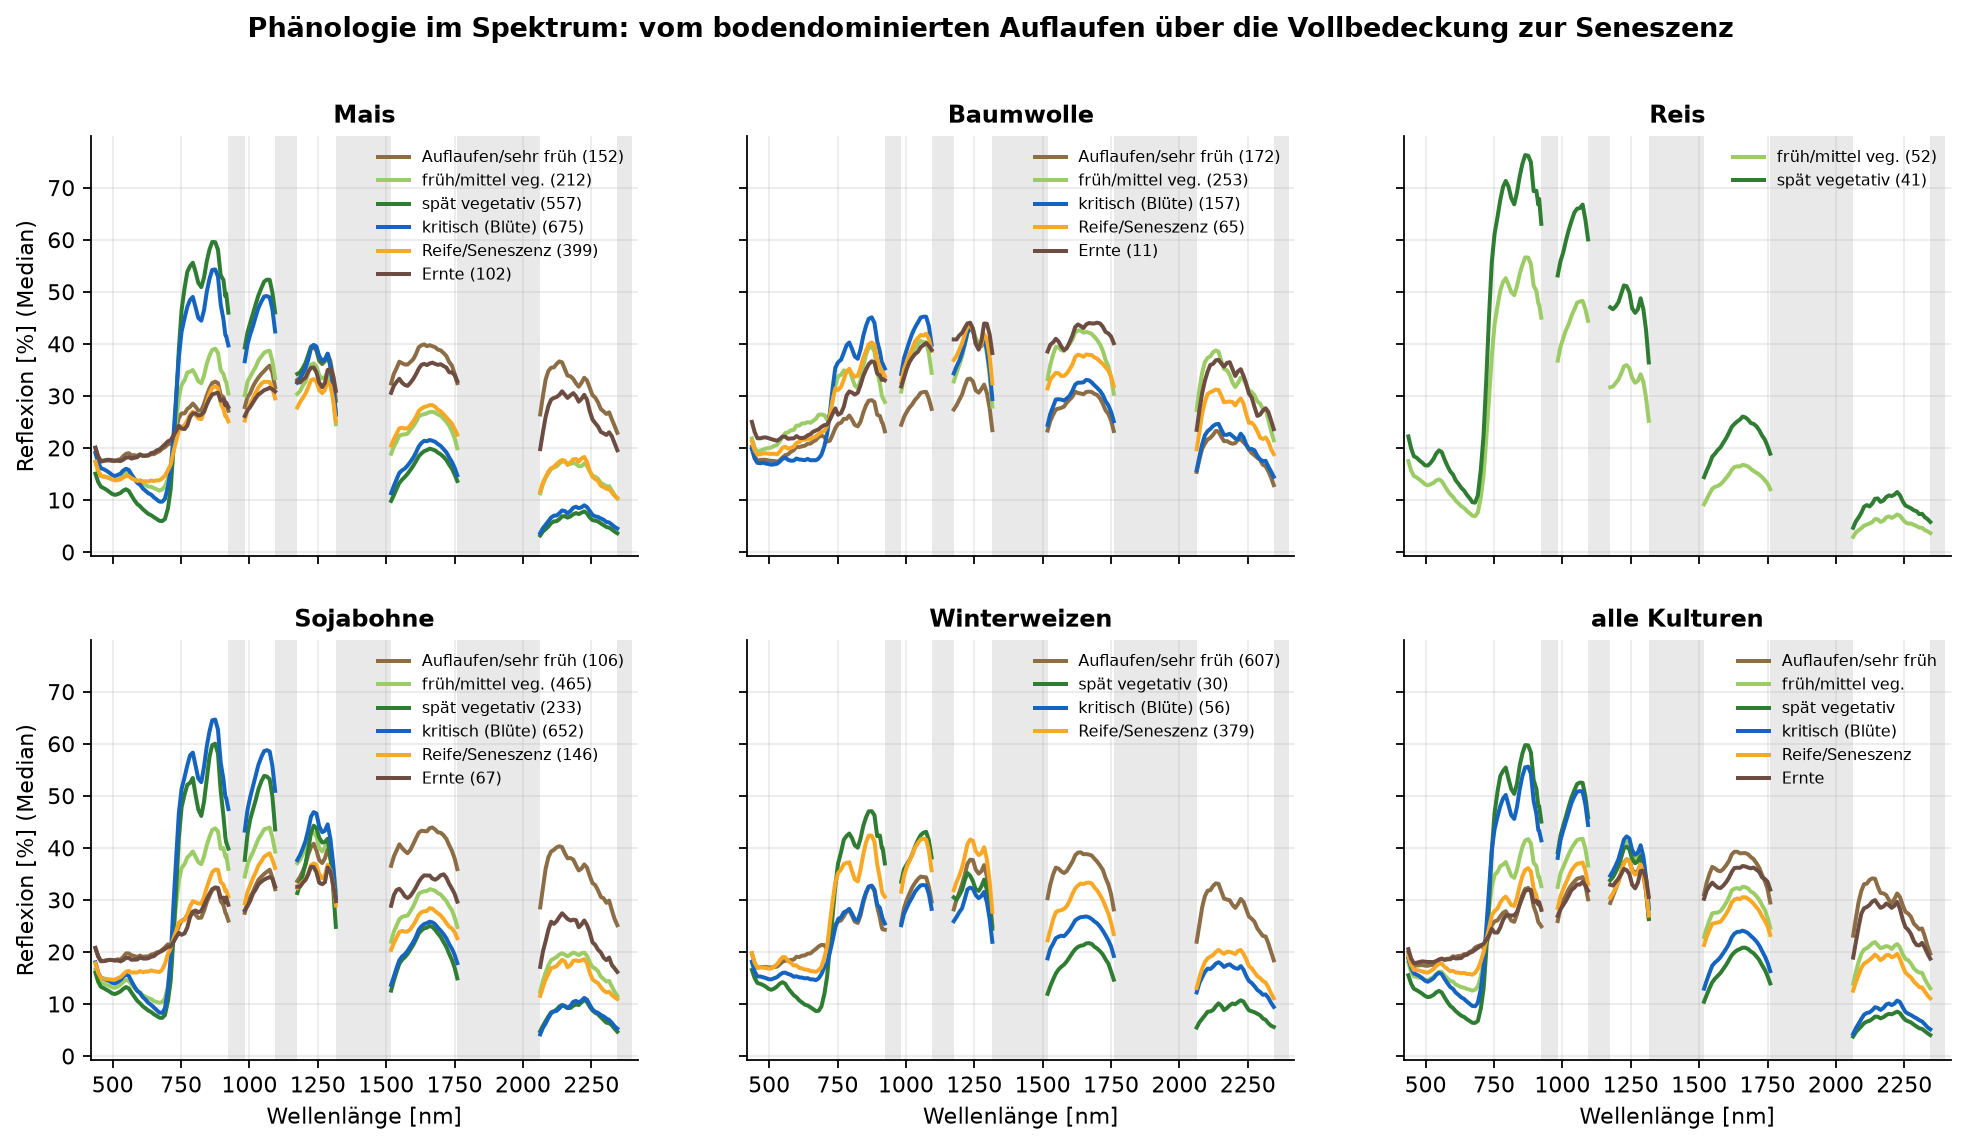

In [7]:
display(Image(FIG / 'eda_spectra_crop.png'))
display(Image(FIG / 'eda_spectra_stage_per_crop.png'))

Die Stadien folgen der Phänologie: im **Auflaufen** und bei der **Ernte** dominiert Boden (flacher VIS-Anstieg, kaum rote Kante, hohe SWIR-Reflexion), bei **voller Bedeckung** (Late/Critical) tiefe Chlorophyllabsorption bei 670 nm, steile rote Kante, hohes NIR-Plateau und niedrige SWIR-Werte durch Blattwasser.

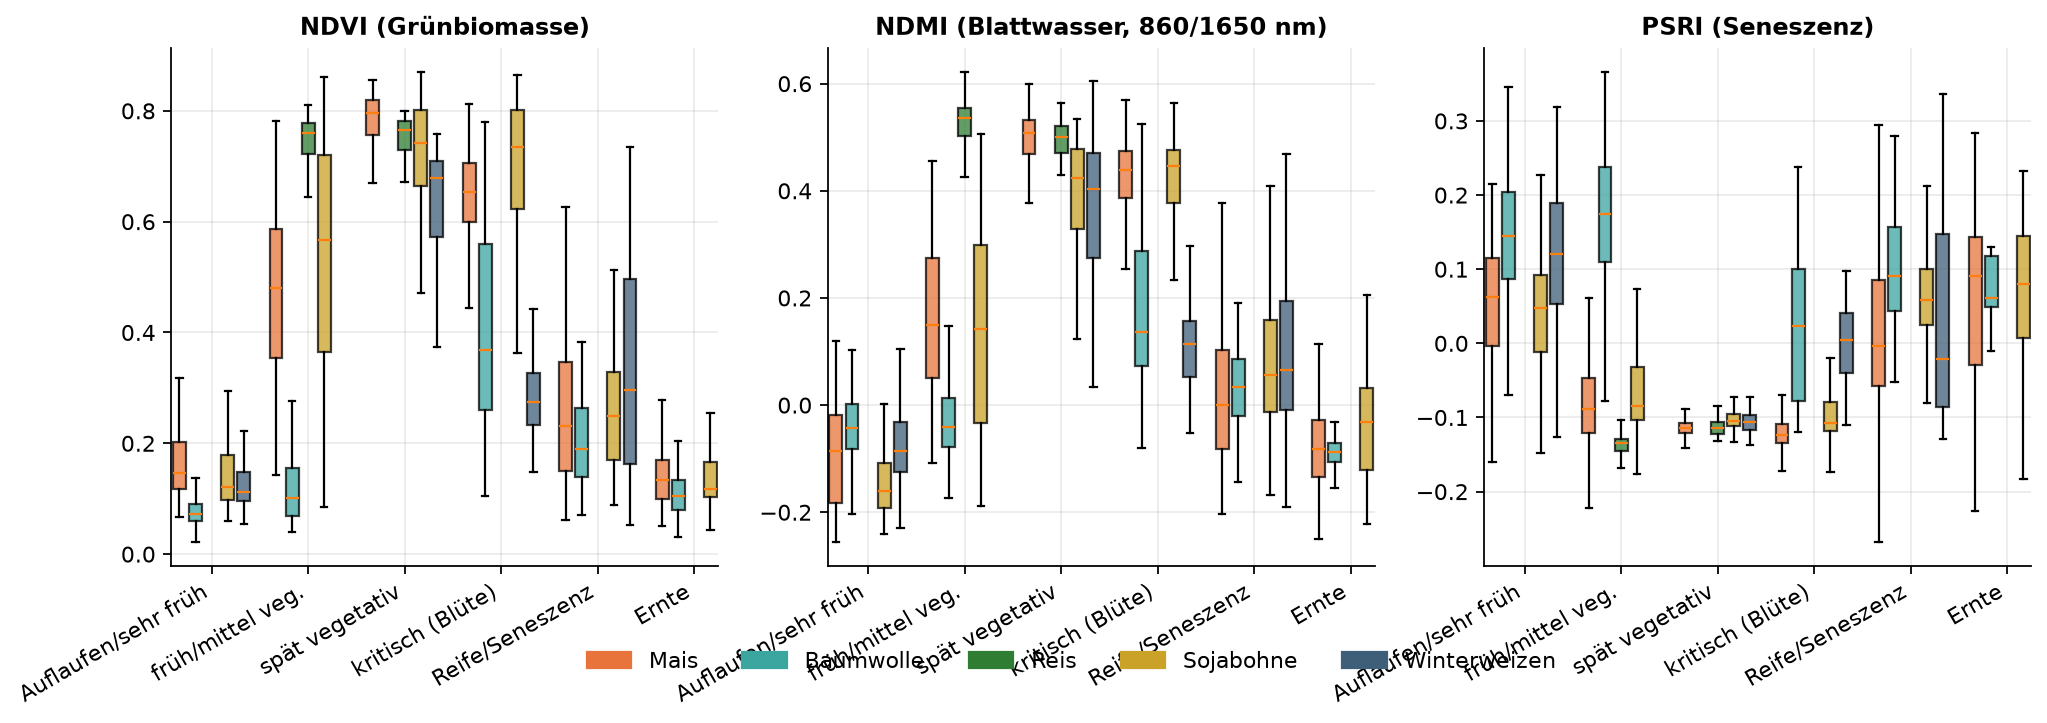

In [8]:
display(Image(FIG / 'eda_indices.png'))

## Überschneidungen zwischen Klassen
Mit dem Spektrum allein trennt ein 5-NN die Kulturen in den bodendominierten Stadien am schlechtesten – dort sieht der Sensor kaum Pflanze.

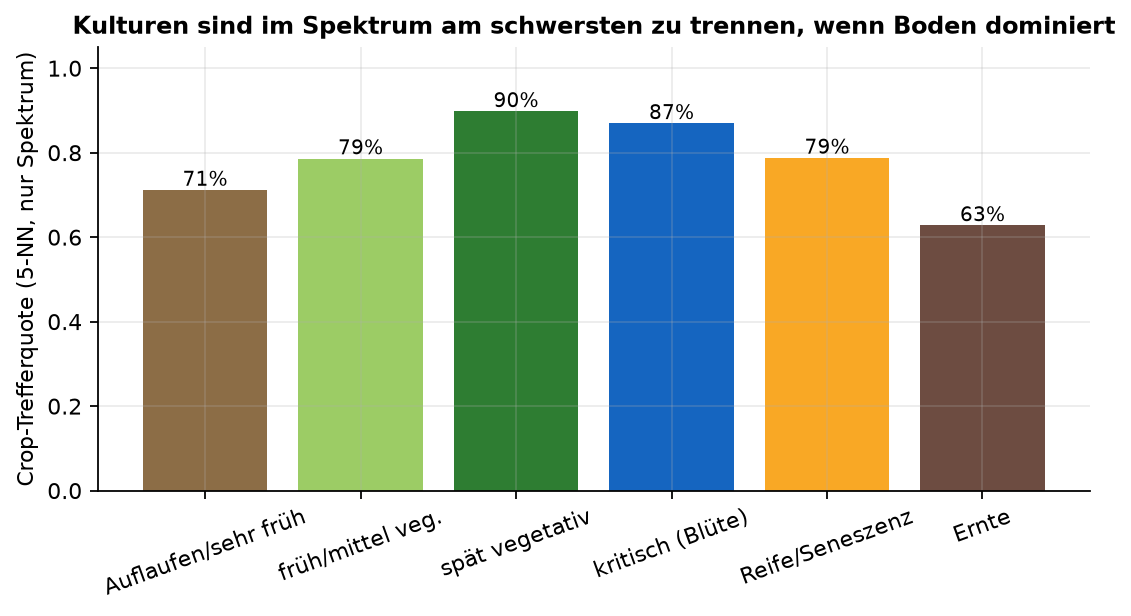

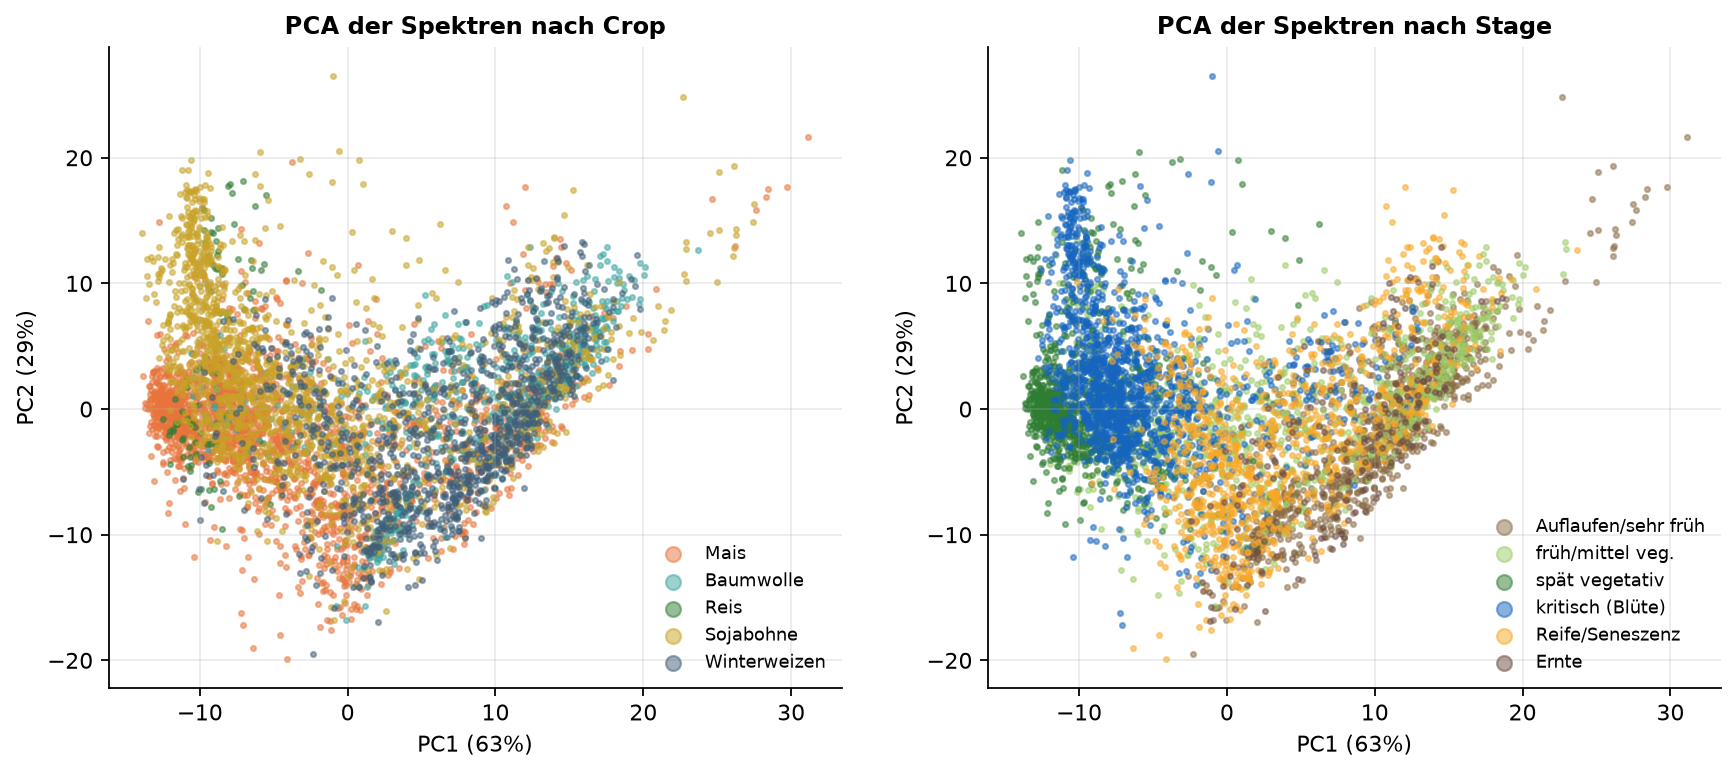

In [9]:
display(Image(FIG / 'eda_crop_separability_by_stage.png'))
display(Image(FIG / 'eda_pca_scatter.png'))

## Redundanz
Benachbarte Bänder sind extrem korreliert; wenige Hauptkomponenten tragen fast die gesamte Varianz → Band-Reduktion ist vielversprechend (Meilenstein 3).

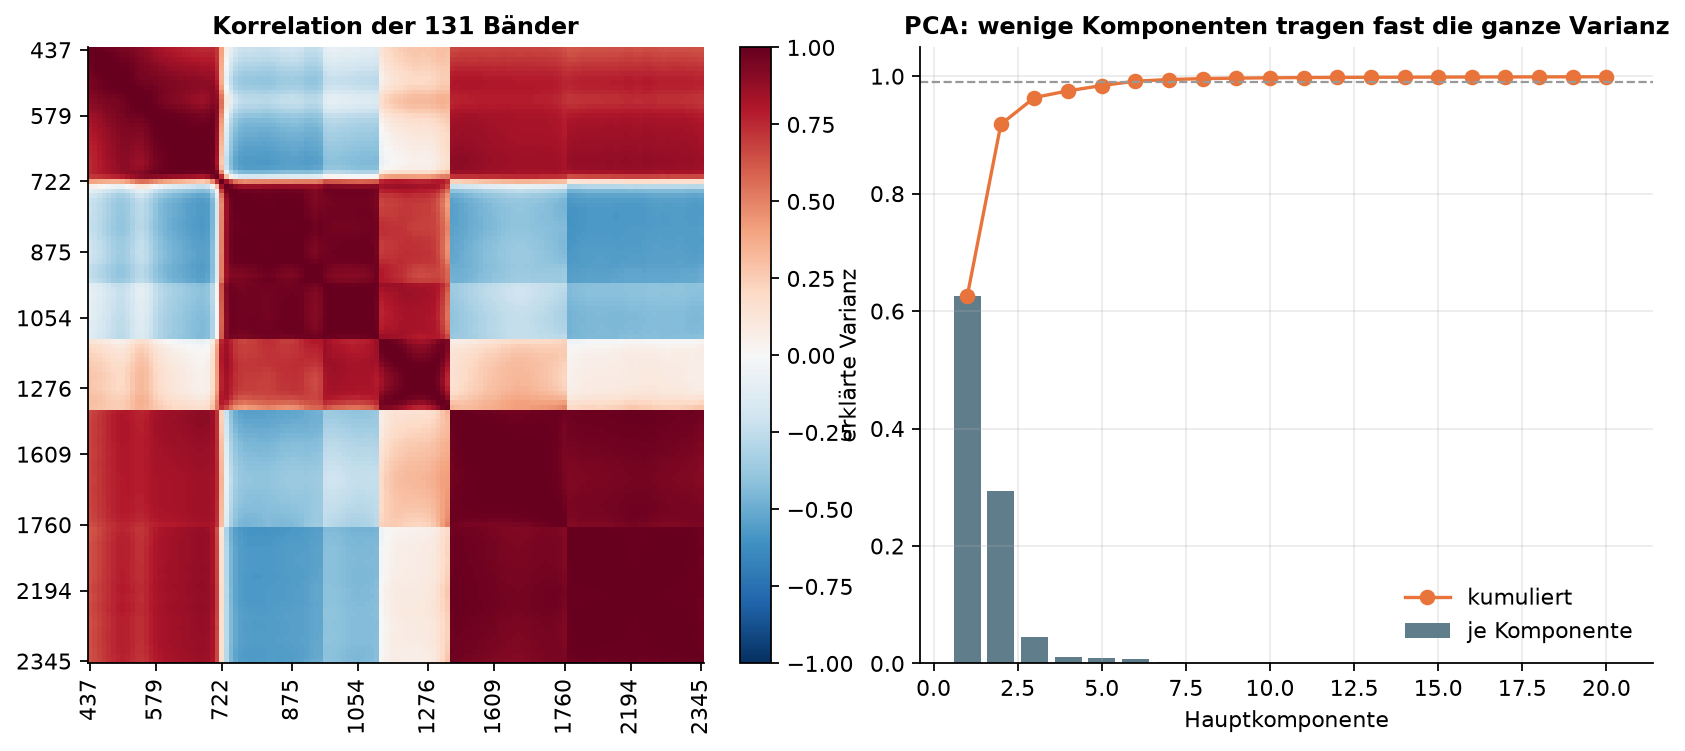

In [10]:
display(Image(FIG / 'eda_correlation_pca.png'))

## Ausreißer und Plausibilität

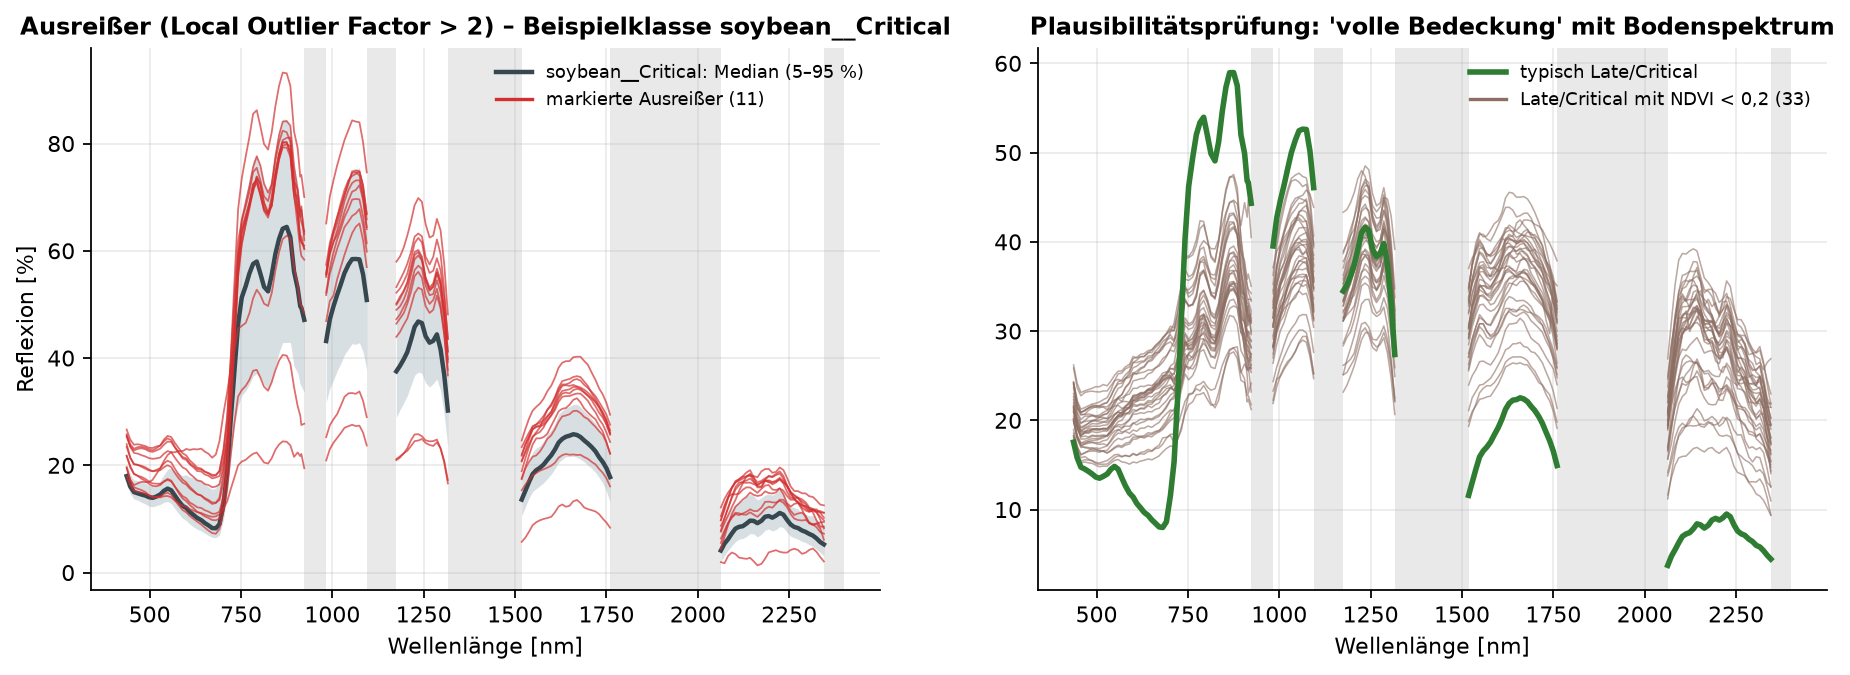

LOF>2: 39 | Late/Critical mit NDVI<0,2: 33


In [11]:
display(Image(FIG / 'eda_outliers.png'))
flags = pd.read_csv(C.TABLES / 'outlier_flags.csv')
print('LOF>2:', flags.flag_lof.sum(), '| Late/Critical mit NDVI<0,2:', flags.flag_low_ndvi.sum())

Die markierten Spektren sind physikalisch plausibel (hellere/dunklere Bestände, Mischpixel). Ihr Entfernen aus dem Training verbessert die CV nicht (siehe `m2_preprocessing`), daher bleiben sie im Datensatz.

## Train vs. Test

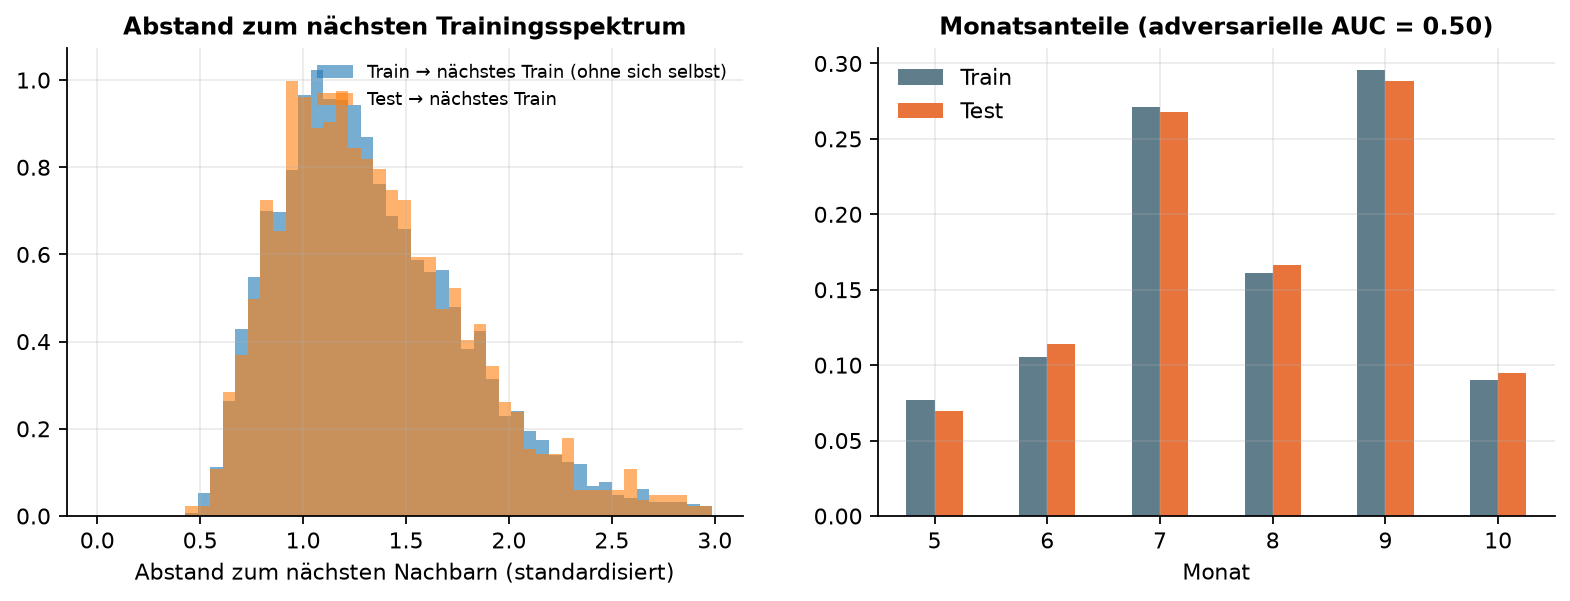

adversarielle AUC: 0.496


In [12]:
display(Image(FIG / 'eda_train_vs_test.png'))
import json
f = json.load(open(C.TABLES / 'eda_facts.json'))
print('adversarielle AUC:', round(f['adversarial_auc'], 3))

AUC ≈ 0,5 und identische Nächste-Nachbar-Distanzen: Der Testdatensatz ist ein Zufallsausschnitt aus demselben Pool. Eine stratifizierte Kreuzvalidierung schätzt die Testnote daher gut.